# Probability boxes for one five-dimensional event

The first three coordinates and last two coordinates are treated as independent probability blocks. For each block, randomly selected sample values define one-dimensional separators at the midpoints of adjacent selected values. The outer separators are the minimum and maximum of all samples. Empty cells and cells containing only one sample are discarded. Each retained box is shrunk to the coordinate range of its assigned samples.

For a retained box $B$, with $n_B$ of the original $N$ samples and hypervolume $V_B$, the constant density is

$$p_B = \frac{n_B}{N V_B}, \qquad \sum_B p_B V_B = \frac{N_{\mathrm{retained}}}{N}.$$

The product of the retained probabilities of the 3D and 2D blocks is the event's retained probability. Discarded sample probability is not redistributed. The chosen sample values set the separators; with uneven spacing, they do not generally coincide with the geometric centers of their final cells. The box weight is one for now.

In [1]:
import os
import shutil
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib_box_overlap")

from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc, rcParams, font_manager
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from cycler import cycler

project_root = Path.cwd()
if project_root.name == "validation":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from bo import make_event_boxes, pick_centers

my_colors = ['navy', 'coral', 'c', 'crimson', 'springgreen', 'gold',
             'dodgerblue', 'hotpink', 'forestgreen', 'moccasin', 'darkred', 'teal']
rc_params = {'axes.labelsize': 14,
             'axes.titlesize': 14,
             'legend.fontsize': 14,
             'xtick.labelsize': 12,
             'ytick.labelsize': 12,
             'text.usetex': True,
             'text.latex.preamble': r'\usepackage{txfonts}',
             'font.size': 14,
             'font.family': 'serif',
             'font.serif': 'times',
             'mathtext.default': 'sf',
             'lines.markeredgewidth': 1,
             'lines.linewidth': 2,
             'axes.prop_cycle': cycler(color=my_colors)}
rcParams.update(rc_params)
missing_tex = [name for name in ("latex", "dvipng") if shutil.which(name) is None]
if missing_tex:
    print(f"Install {', '.join(missing_tex)} separately to use LaTeX text in plots.")
    rcParams["text.usetex"] = False
if rcParams["text.usetex"] is False:
    try:
        font_manager.findfont("Times", fallback_to_default=False)
    except ValueError:
        print("Install a Times font separately for the requested plot font.")
        rcParams["font.serif"] = ["DejaVu Serif"]


Install dvipng separately to use LaTeX text in plots.
Install a Times font separately for the requested plot font.


## Choose the event and the number of selected samples

`n_centers_3d` and `n_centers_2d` control the number of intervals per coordinate. The maximum possible box counts are their third and second powers, respectively; empty and one-sample cells are removed. Change `idx` to inspect another event. A warning appears if more than 0.1% of the event probability is discarded.

In [2]:
idx = 1
n_centers_3d = 4
n_centers_2d = 8
seed = 91
save_plots = False

samples = np.load(project_root / "validation" / "ARAK_samples" / f"event_{idx}.npy", mmap_mode="r")
event = make_event_boxes(samples, n_centers=(n_centers_3d, n_centers_2d),
                         rng=np.random.default_rng(seed))
boxes_3d, boxes_2d = event

# Recreate the random choices with the same seed for plotting.
rng = np.random.default_rng(seed)
selected_3d = pick_centers(samples[:, :3], n_centers_3d, rng)
selected_2d = pick_centers(samples[:, 3:], n_centers_2d, rng)

for name, boxes in (("3D", boxes_3d), ("2D", boxes_2d)):
    print(f"{name}: {boxes.n_boxes} retained boxes, retained probability = "
          f"{boxes.retained_probability:.6f}")
print(f"Event retained probability = {event.retained_probability:.6f}")

3D: 59 retained boxes, retained probability = 0.999900
2D: 43 retained boxes, retained probability = 0.999800
Event retained probability = 0.999700


## Samples and box boundaries

The lower triangle shows joint sample scatter. Navy outlines are projections of the final sample-bounded boxes for pairs of coordinates in the same block. Coral dots mark the selected samples that set those boundaries; a dot can lie outside the retained boxes when its cell contained only one sample. Cross-block panels show the original joint samples only. A projection of a 3D box can overlap another projection even though the full 3D boxes have disjoint interiors.

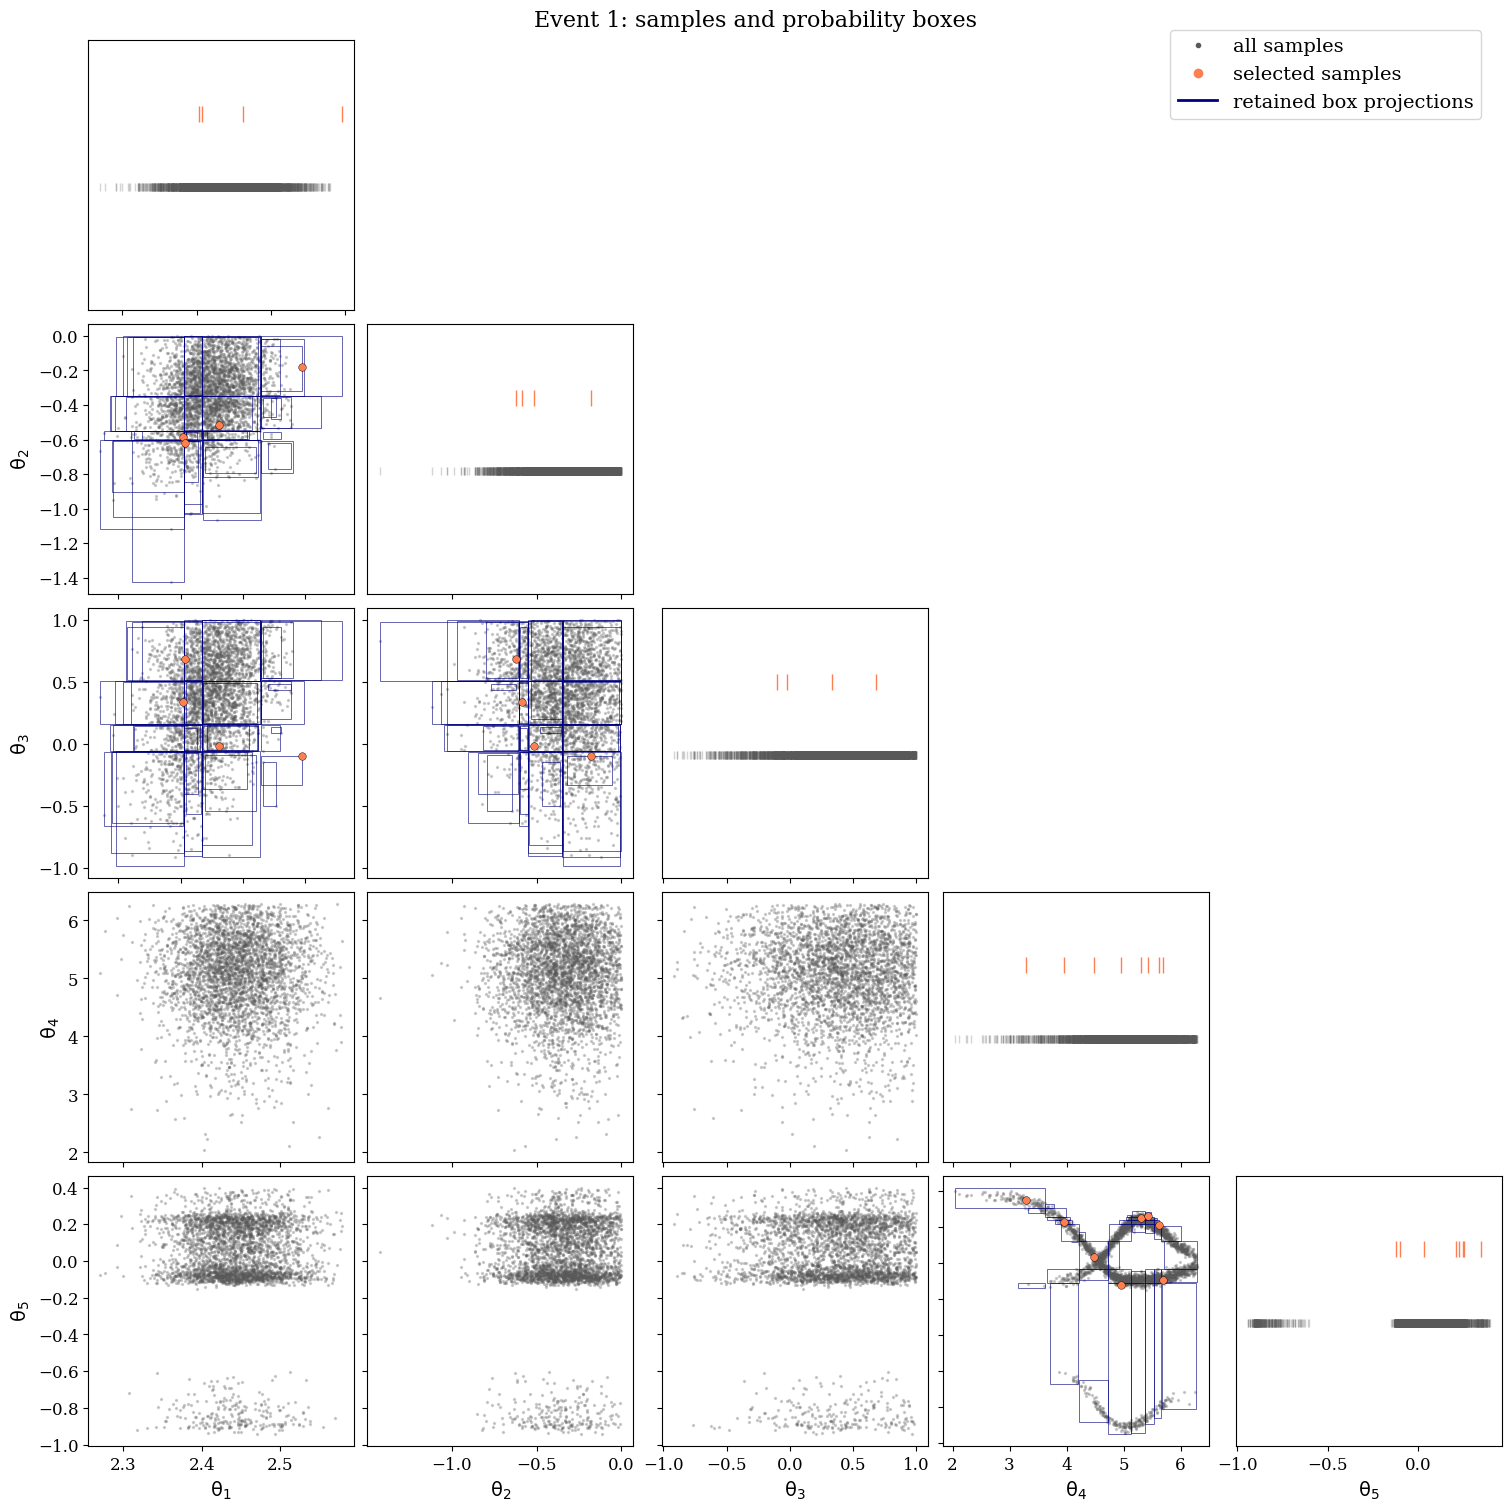

In [3]:
labels = [r'$\theta_1$', r'$\theta_2$', r'$\theta_3$',
          r'$\theta_4$', r'$\theta_5$']
shown = samples[::max(1, len(samples) // 3000)]
fig, axes = plt.subplots(5, 5, figsize=(15, 15), constrained_layout=True)
for row in range(5):
    for col in range(5):
        ax = axes[row, col]
        if row < col:
            ax.set_visible(False)
            continue
        if row == col:
            ax.plot(shown[:, col], np.zeros(len(shown)), '|', color='0.35', alpha=.25)
            chosen = selected_3d[:, col] if col < 3 else selected_2d[:, col - 3]
            ax.plot(chosen, np.full(len(chosen), .06), '|', color='coral', markersize=11)
            ax.set_ylim(-.1, .12)
            ax.set_yticks([])
        else:
            ax.scatter(shown[:, col], shown[:, row], s=2, color='0.35', alpha=.25,
                       rasterized=True)
            if row < 3:
                boxes, chosen, x, y = boxes_3d, selected_3d, col, row
            elif col >= 3:
                boxes, chosen, x, y = boxes_2d, selected_2d, col - 3, row - 3
            else:
                boxes = None
            if boxes is not None:
                for lower, upper in zip(boxes.lower, boxes.upper):
                    ax.add_patch(Rectangle((lower[x], lower[y]),
                                           upper[x] - lower[x], upper[y] - lower[y],
                                           fill=False, edgecolor='navy', linewidth=.7,
                                           alpha=.6))
                ax.scatter(chosen[:, x], chosen[:, y], s=30, color='coral',
                           edgecolor='black', linewidth=.3, zorder=5)
        if row == 4:
            ax.set_xlabel(labels[col])
        else:
            ax.set_xticklabels([])
        if col == 0 and row > 0:
            ax.set_ylabel(labels[row])
        elif col > 0 and row > col:
            ax.set_yticklabels([])

fig.legend(handles=[Line2D([], [], marker='.', linestyle='', color='0.35', label='all samples'),
                    Line2D([], [], marker='o', linestyle='', color='coral', label='selected samples'),
                    Line2D([], [], color='navy', label='retained box projections')],
           loc='upper right', bbox_to_anchor=(.99, .99), frameon=True)
fig.suptitle(f'Event {idx}: samples and probability boxes', fontsize=16)
if save_plots:
    fig.savefig(project_root / 'validation' / f'event_{idx}_samples_boxes.jpg', dpi=200)
plt.show()

## Density in the retained boxes

Color is the recomputed constant density in each full-dimensional box after shrinking. The first three panels project 3D boxes onto coordinate pairs, so several differently colored boxes can appear in the same projected area. The final panel shows the actual nonoverlapping 2D boxes. The color scales are separate because 3D and 2D densities have different units.

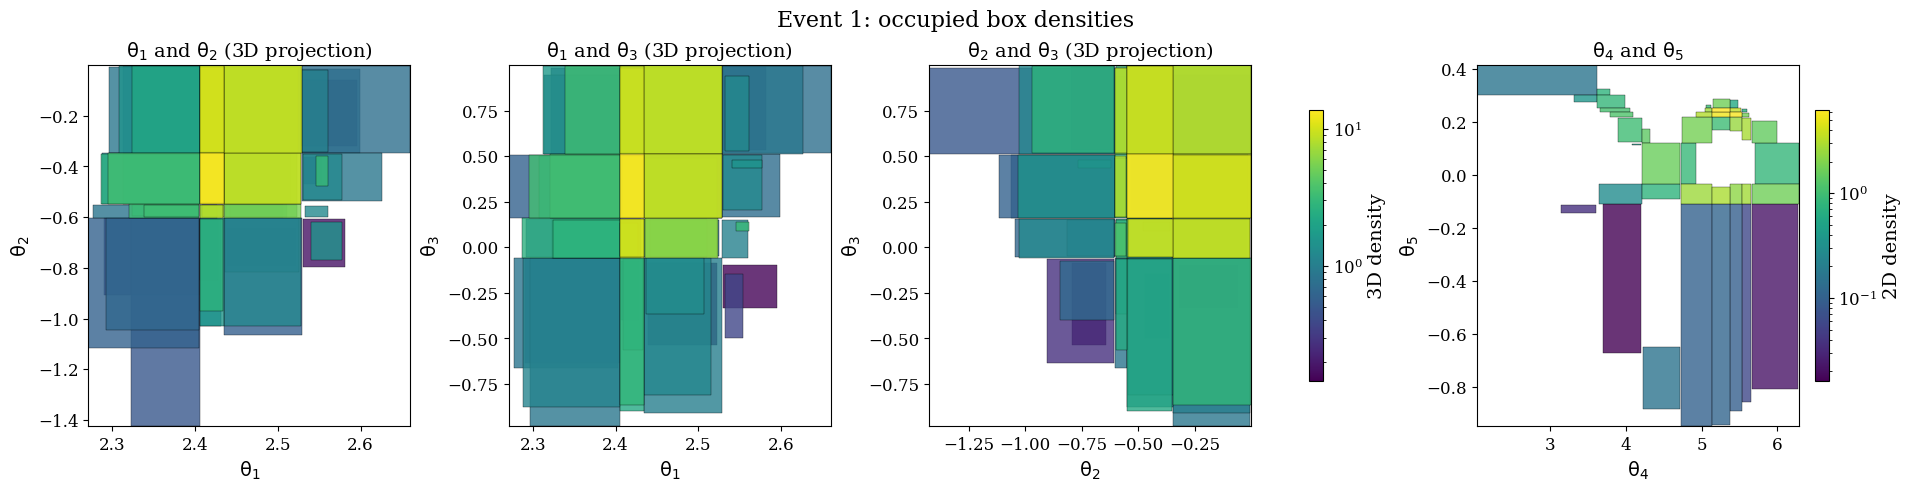

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.8), constrained_layout=True)
norm_3d = LogNorm(vmin=boxes_3d.density.min(), vmax=boxes_3d.density.max())
norm_2d = LogNorm(vmin=boxes_2d.density.min(), vmax=boxes_2d.density.max())
for ax, (x, y) in zip(axes, ((0, 1), (0, 2), (1, 2), (3, 4))):
    if x < 3:
        boxes, norm, local_x, local_y = boxes_3d, norm_3d, x, y
    else:
        boxes, norm, local_x, local_y = boxes_2d, norm_2d, x - 3, y - 3
    # Draw high-density boxes last where their 3D projections overlap.
    for k in np.argsort(boxes.density):
        lower, upper = boxes.lower[k], boxes.upper[k]
        ax.add_patch(Rectangle((lower[local_x], lower[local_y]),
                               upper[local_x] - lower[local_x],
                               upper[local_y] - lower[local_y],
                               facecolor=plt.cm.viridis(norm(boxes.density[k])),
                               edgecolor='black', linewidth=.3, alpha=.8))
    ax.set_xlim(samples[:, x].min(), samples[:, x].max())
    ax.set_ylim(samples[:, y].min(), samples[:, y].max())
    ax.set_xlabel(labels[x])
    ax.set_ylabel(labels[y])
    suffix = ' (3D projection)' if x < 3 else ''
    ax.set_title(f'{labels[x]} and {labels[y]}{suffix}')

fig.colorbar(ScalarMappable(norm=norm_3d, cmap='viridis'), ax=list(axes[:3]),
             shrink=.75, label=r'3D density')
fig.colorbar(ScalarMappable(norm=norm_2d, cmap='viridis'), ax=axes[3],
             shrink=.75, label=r'2D density')
fig.suptitle(f'Event {idx}: occupied box densities', fontsize=16)
if save_plots:
    fig.savefig(project_root / 'validation' / f'event_{idx}_densities.jpg', dpi=200)
plt.show()

## Two-event overlap

The overlap is computed by sorted C++ loops, checking the second (2D) block first.
For intersecting boxes $A,B$, let $v$ be their intersection volume and $V_A,V_B$
their full volumes. Their contribution is

$$v p_A p_B\frac{w_A/V_A+w_B/V_B}{1/V_A+1/V_B}.$$

The event result is the product of the two block sums. This assumes unit weights
or a weight that factors into one function for each independent block. A general
weight coupling the blocks cannot be represented by the stored block weights.

The sample histogram estimate uses shared 2D and 3D bin edges and unit weights.
Differences from the box result reflect the density approximation and histogram
sampling noise. The second comparison paints the box densities onto a dense
midpoint grid; it should approach the exact C++ answer as resolution increases.
Choose `idx1` and `idx2` below to compare other events.


In [5]:
sys.path.insert(0, str(project_root / "validation"))
from bo import overlap_1v1, prepare_event
from compare_overlap import compare_block

idx1, idx2 = 66, 71
samples_a = np.load(project_root / "validation" / "ARAK_samples" / f"event_{idx1}.npy", mmap_mode="r")
samples_b = np.load(project_root / "validation" / "ARAK_samples" / f"event_{idx2}.npy", mmap_mode="r")
event_a = make_event_boxes(samples_a, rng=np.random.default_rng(91 + idx1))
event_b = make_event_boxes(samples_b, rng=np.random.default_rng(91 + idx2))
prepared_a, prepared_b = prepare_event(event_a), prepare_event(event_b)
exact = overlap_1v1(prepared_a, prepared_b)
print(f"Events {idx1} and {idx2}: exact box overlap = {exact:.8g}")
print(" bins     sample histogram      box midpoint grid       grid relative error")
for bins in (24, 48, 96, 192):
    sample_estimate, grid_estimate = 1., 1.
    for columns, a, b in zip((slice(0, 3), slice(3, 5)), event_a.blocks, event_b.blocks):
        sample_value, grid_value = compare_block(samples_a[:, columns], samples_b[:, columns],
                                                 a, b, bins)
        sample_estimate *= sample_value
        grid_estimate *= grid_value
    relative_error = abs(grid_estimate / exact - 1) if exact != 0 else float("nan")
    print(f"{bins:5d}     {sample_estimate:16.8g}     {grid_estimate:16.8g}"
          f"     {relative_error:16.3%}")


Events 66 and 71: exact box overlap = 1.1359572
 bins     sample histogram      box midpoint grid       grid relative error
   24           0.24451041            1.0982038               3.323%
   48           0.26307779            1.2138259               6.855%
   96           0.26732598            1.1985391               5.509%


  192          0.069511101            1.1334698               0.219%


### Where the two events intersect

The top row uses analytic box intersections; the bottom row uses the product
of the dense sample histograms. Navy and coral identify events A and B. Outlines
show boxes in the top row; contours show 10%, 50%, and 90% of each event's
marginal histogram peak in the bottom row. Blank pixels have zero overlap. The
color scale is shared between methods within each column.

For the 3D block, each panel shows
$G_{ij}(\theta_i,\theta_j)=\int P_A(\boldsymbol\theta)P_B(\boldsymbol\theta)\,d\theta_k$,
where $k$ is the omitted coordinate. Full 3D intersections are computed **before**
projection. Each panel's integral therefore equals the full 3D block overlap;
separately projecting the two PDFs and multiplying them would not do this.

Box pixels average the exact intersection contributions over their area, and
their integrals are checked against the C++ result. The second figure zooms to
the nonzero overlap support to make the narrow 2D intersection visible.
Use the `idx1`, `idx2` selected above and change `intersection_bins` to inspect
histogram resolution. Both plots use unit weights.


Install dvipng separately for LaTeX plot text.


Install a Times font separately for the requested plot font.


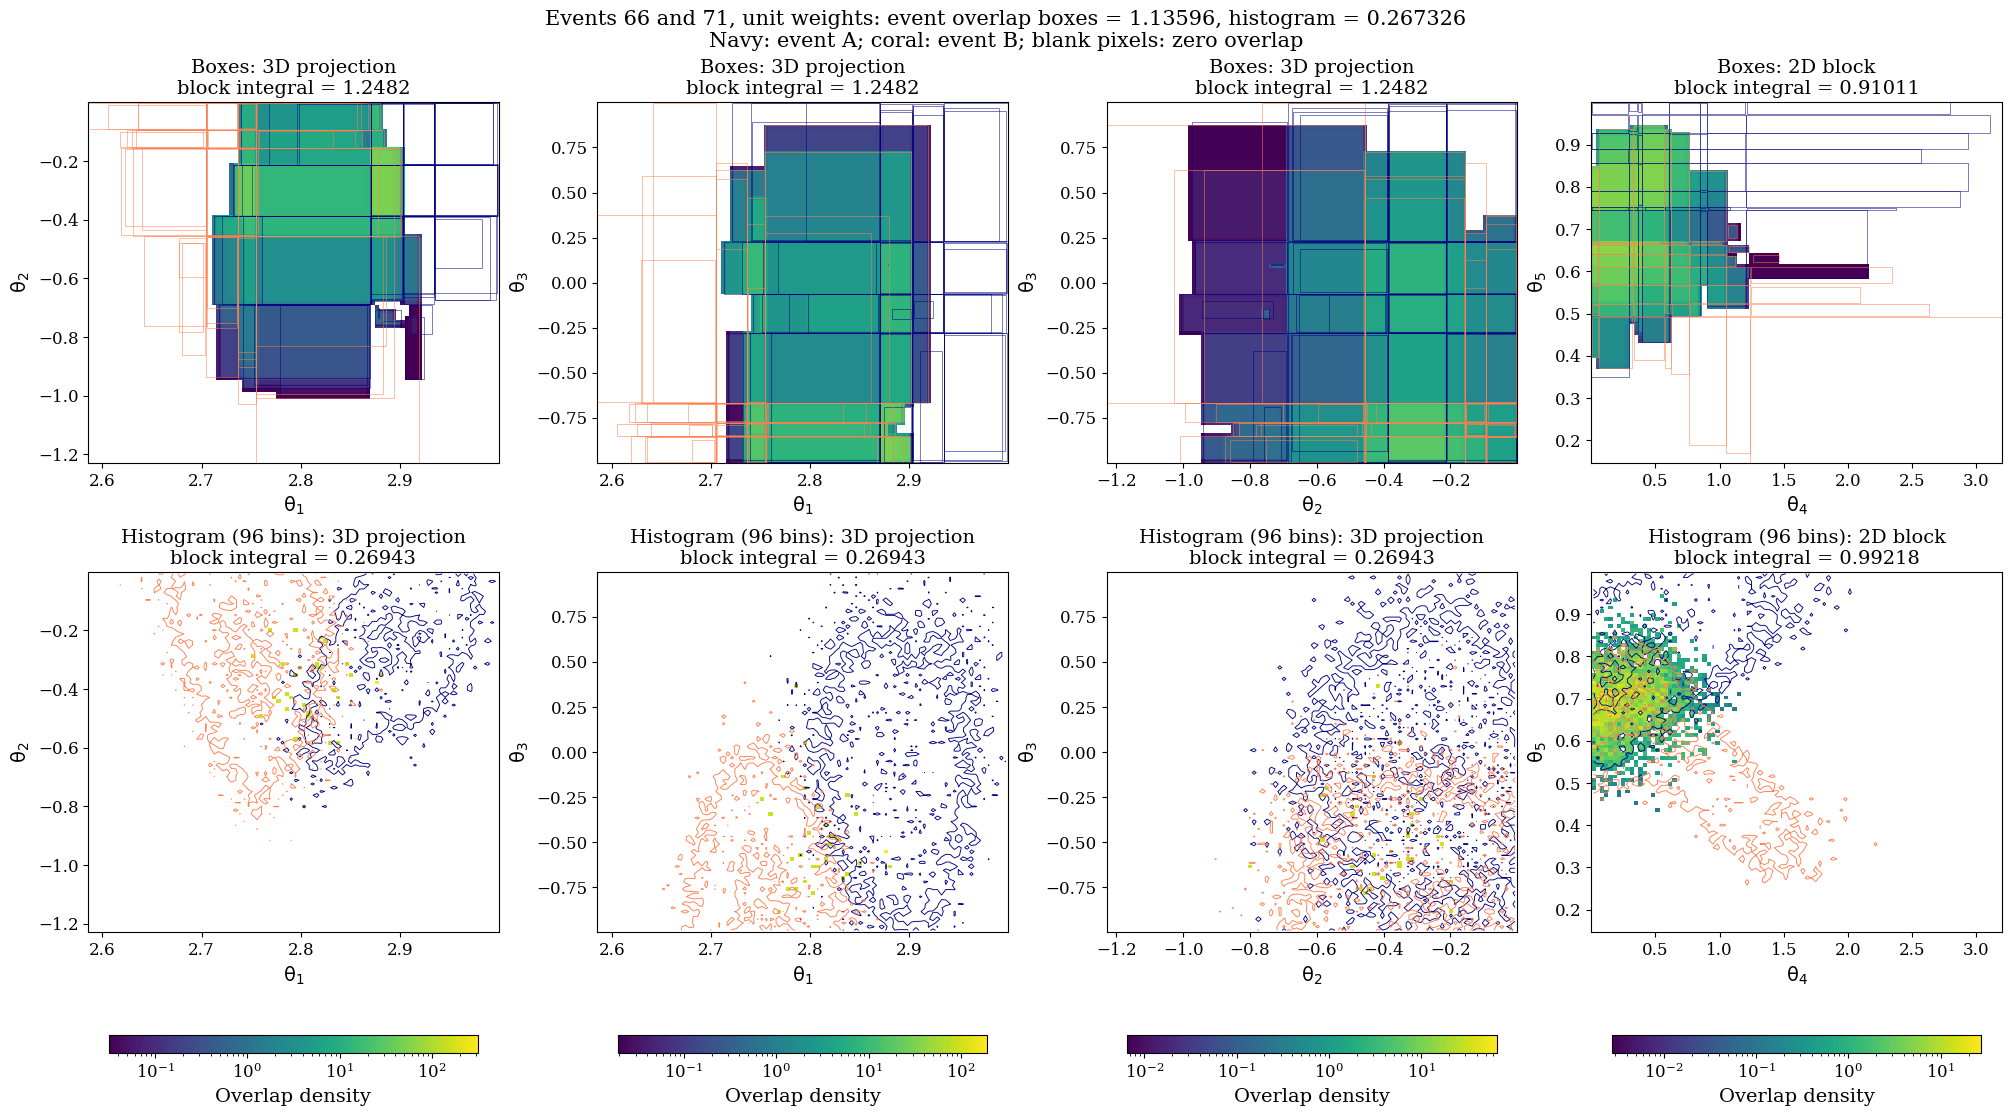

Install dvipng separately for LaTeX plot text.


Install a Times font separately for the requested plot font.


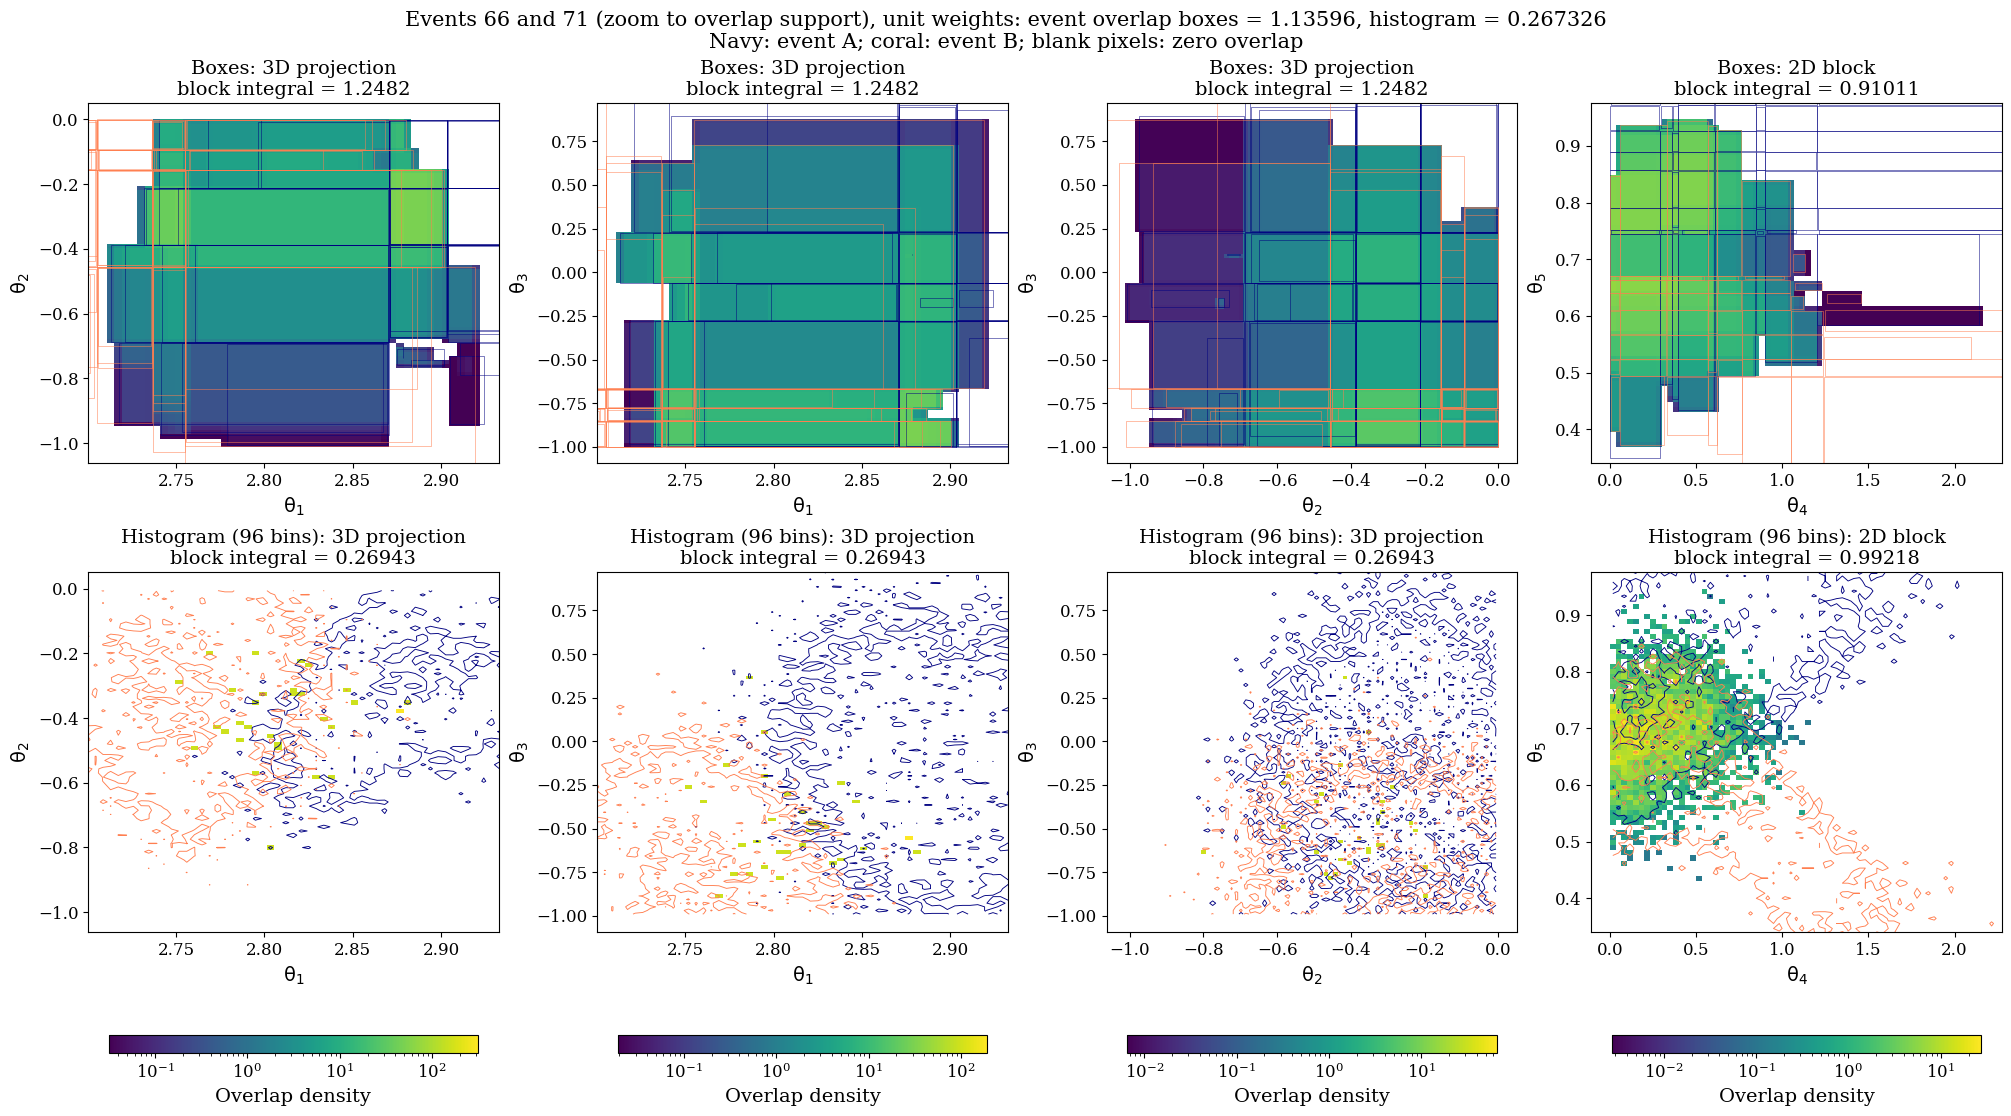

In [6]:
from plot_1v1_overlap import plot_intersection

intersection_bins = 96
intersection_folder = project_root / "validation" / "pair_finder_results"
intersection_folder.mkdir(exist_ok=True)
fig, intersection_maps = plot_intersection(
    samples_a, samples_b, event_a, event_b, idx1, idx2, bins=intersection_bins,
    output=intersection_folder / f"1v1_{idx1}_{idx2}.jpg")
plt.show()
fig, _ = plot_intersection(
    samples_a, samples_b, event_a, event_b, idx1, idx2, bins=intersection_bins,
    output=intersection_folder / f"1v1_{idx1}_{idx2}_zoom.jpg", zoom=True)
plt.show()


## Filtering event pairs

The event tree stores overall bounds from both independent blocks and tests 2D
bounds first. At surviving leaves, sorted box loops test for one intersection in
each block. Pair selection uses geometry; calculation uses densities and weights.
The index can be built from selected detection boxes independently of the full
boxes used for the integral.


In [7]:
from bo import build_index, find_NvN, find_1vN, prepare_events, overlap_NvN_pairs

example_events = [make_event_boxes(
    np.load(project_root / "validation" / "ARAK_samples" / f"event_{i}.npy", mmap_mode="r"),
    rng=np.random.default_rng(91+i)) for i in range(100)]
full = prepare_events(example_events)
index = build_index(full)
pairs = find_NvN(index)
values = overlap_NvN_pairs(full, pairs)
print(f"100 events: {len(pairs)} intersecting pairs out of 4,950 possible pairs")
print("First pairs and their integrals:")
for pair, value in zip(pairs[:5], values[:5]):
    print(f"  {tuple(pair)}: {value:.8g}")


100 events: 820 intersecting pairs out of 4,950 possible pairs
First pairs and their integrals:
  (0, 5): 3.6261054e-06
  (0, 9): 5.8623187e-05
  (0, 12): 0.013930844
  (0, 15): 0.049569574
  (0, 16): 0.0088904034


/tmp/ipykernel_192236/3962420222.py:3: RuntimeWarning: Event boxes retain 99.8800% of the sample probability (more than 0.1% was discarded)
  example_events = [make_event_boxes(


### 100v1 and 100v5

Only the 2D block is displayed. Crimson identifies events intersecting the query
in both full blocks; navy outlines are the query boxes.

![100v1](pair_finder_results/100v1.jpg)

![100v5](pair_finder_results/100v5.jpg)

### All pairs among 100 events

All 4,950 pairs are compared, including pairs with zero in either estimate.
The histogram uses 48 bins per coordinate on grids shared by each event pair.
The estimates differ because they describe the sampled and box-approximated
densities. Small histogram overlaps can be zero because of finite sampling;
box overlaps can remain positive across gaps enclosed by a box.

![Histogram comparison](pair_finder_results/histogram_comparison.jpg)

### Computation cost

The curves use 20 geometrically spaced integer event counts from 2 to all available events.
Box-generation and C++ preparation times are cumulative per-event measurements,
excluding file opening but including mapped sample reads. Pair finding and accumulation use bounded batches,
so all matching pairs are never retained together. Index building, pair finding and filtered accumulation are
measured separately for each prefix. The 1vN query is the final event; its self match
is removed at the full-set endpoint. Times are single-run wall times.

![Cost scaling](pair_finder_results/scaling.jpg)

Numeric results: [timings](pair_finder_results/timings.csv),
[all-pair histogram comparison](pair_finder_results/histogram_comparison.csv),
and [100v5 overlaps](pair_finder_results/100v5.csv).

Reproduce with `python validation/validate_pair_finder.py` using `gw`.

Sample files are read one event at a time; pairwise histogram validation
opens at most two sample maps. Only compact boxes are kept across events.
